In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

In [23]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing()

df = pd.DataFrame(data.data, columns=data.feature_names)

df['MedHouseVal'] = data.target

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [24]:
print(df.shape)
print(df.columns)
df.info()
print(df.describe())
print(df.isnull().sum())

(20640, 9)
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.47

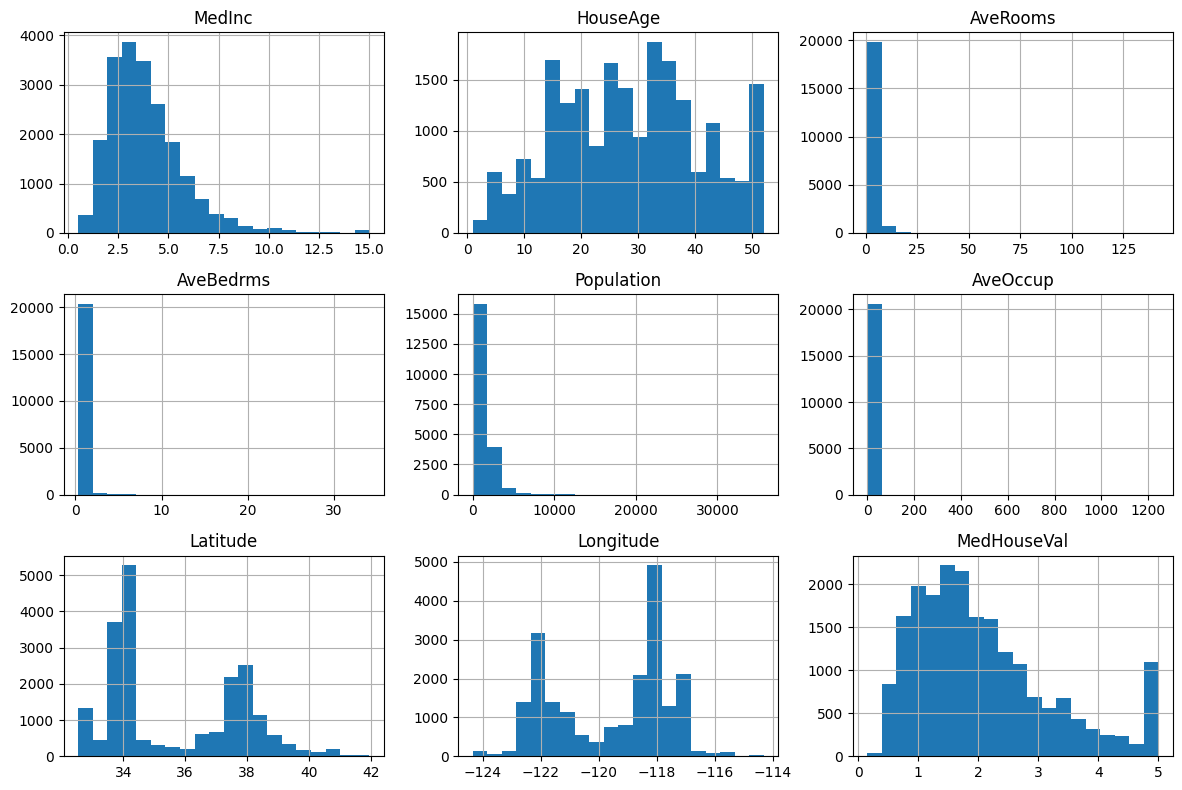

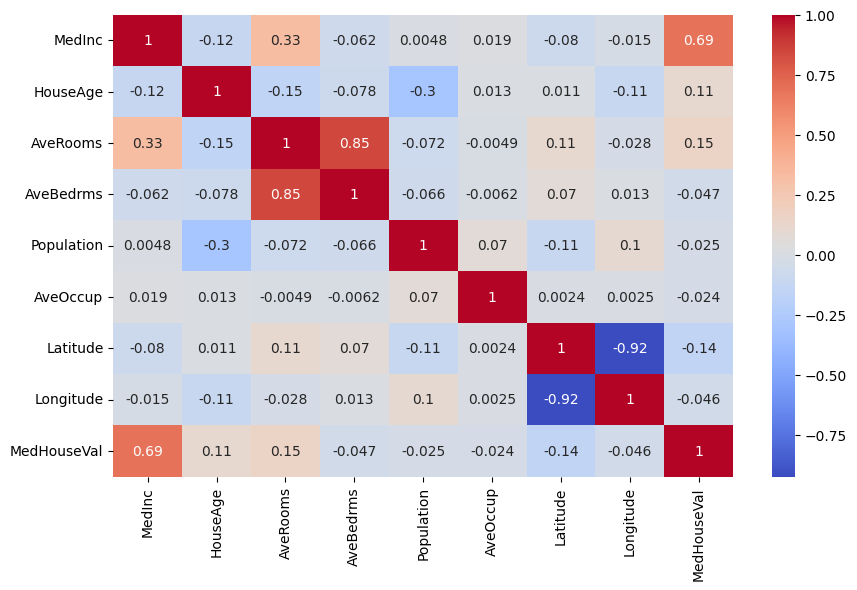

In [25]:
df.hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

In [26]:
df['Price_Category'] = (df['MedHouseVal'] > df['MedHouseVal'].median()).astype(int)

print(df['Price_Category'].value_counts())

Price_Category
0    10323
1    10317
Name: count, dtype: int64


In [27]:
X = df.drop(['MedHouseVal', 'Price_Category'], axis=1)

y = df['Price_Category']

print(X.head())
print(y.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  
0    1
1    1
2    1
3    1
4    1
Name: Price_Category, dtype: int64


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape)
print(X_test.shape)

(16512, 8)
(4128, 8)


In [30]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [31]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model Trained Successfully")

Model Trained Successfully


In [32]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[1 1 0 0 0 1 1 0 1 1]


In [33]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.8313953488372093
Accuracy Percentage: 83.13953488372093


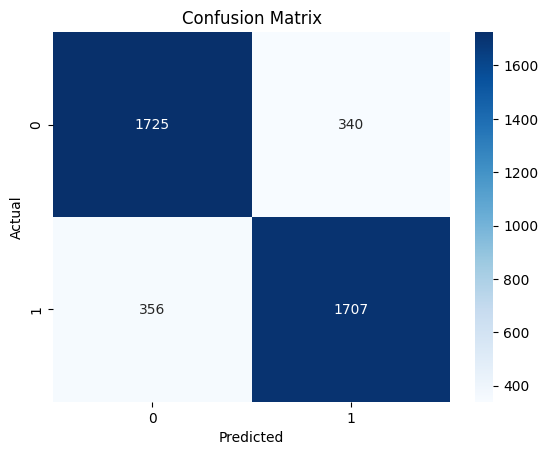

In [34]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [35]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.84      0.83      2065
           1       0.83      0.83      0.83      2063

    accuracy                           0.83      4128
   macro avg       0.83      0.83      0.83      4128
weighted avg       0.83      0.83      0.83      4128



In [36]:
y_prob = model.predict_proba(X_test)

print(y_prob[:10])

[[0.16863972 0.83136028]
 [0.03997621 0.96002379]
 [0.51294533 0.48705467]
 [0.67339264 0.32660736]
 [0.93378219 0.06621781]
 [0.25589457 0.74410543]
 [0.13979035 0.86020965]
 [0.69017956 0.30982044]
 [0.0613678  0.9386322 ]
 [0.01988395 0.98011605]]


In [37]:
new_house = pd.DataFrame({
    'MedInc': [5.0],
    'HouseAge': [20],
    'AveRooms': [6.0],
    'AveBedrms': [1.0],
    'Population': [1000],
    'AveOccup': [3.0],
    'Latitude': [37.0],
    'Longitude': [-122.0]
})

new_house_scaled = scaler.transform(new_house)

prediction = model.predict(new_house_scaled)

probability = model.predict_proba(new_house_scaled)

print("Predicted Category:", prediction[0])
print("Probability:", probability)

Predicted Category: 1
Probability: [[0. 1.]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [38]:
if prediction[0] == 0:
    print("House belongs to Low Price Category")
else:
    print("House belongs to High Price Category")

House belongs to High Price Category
